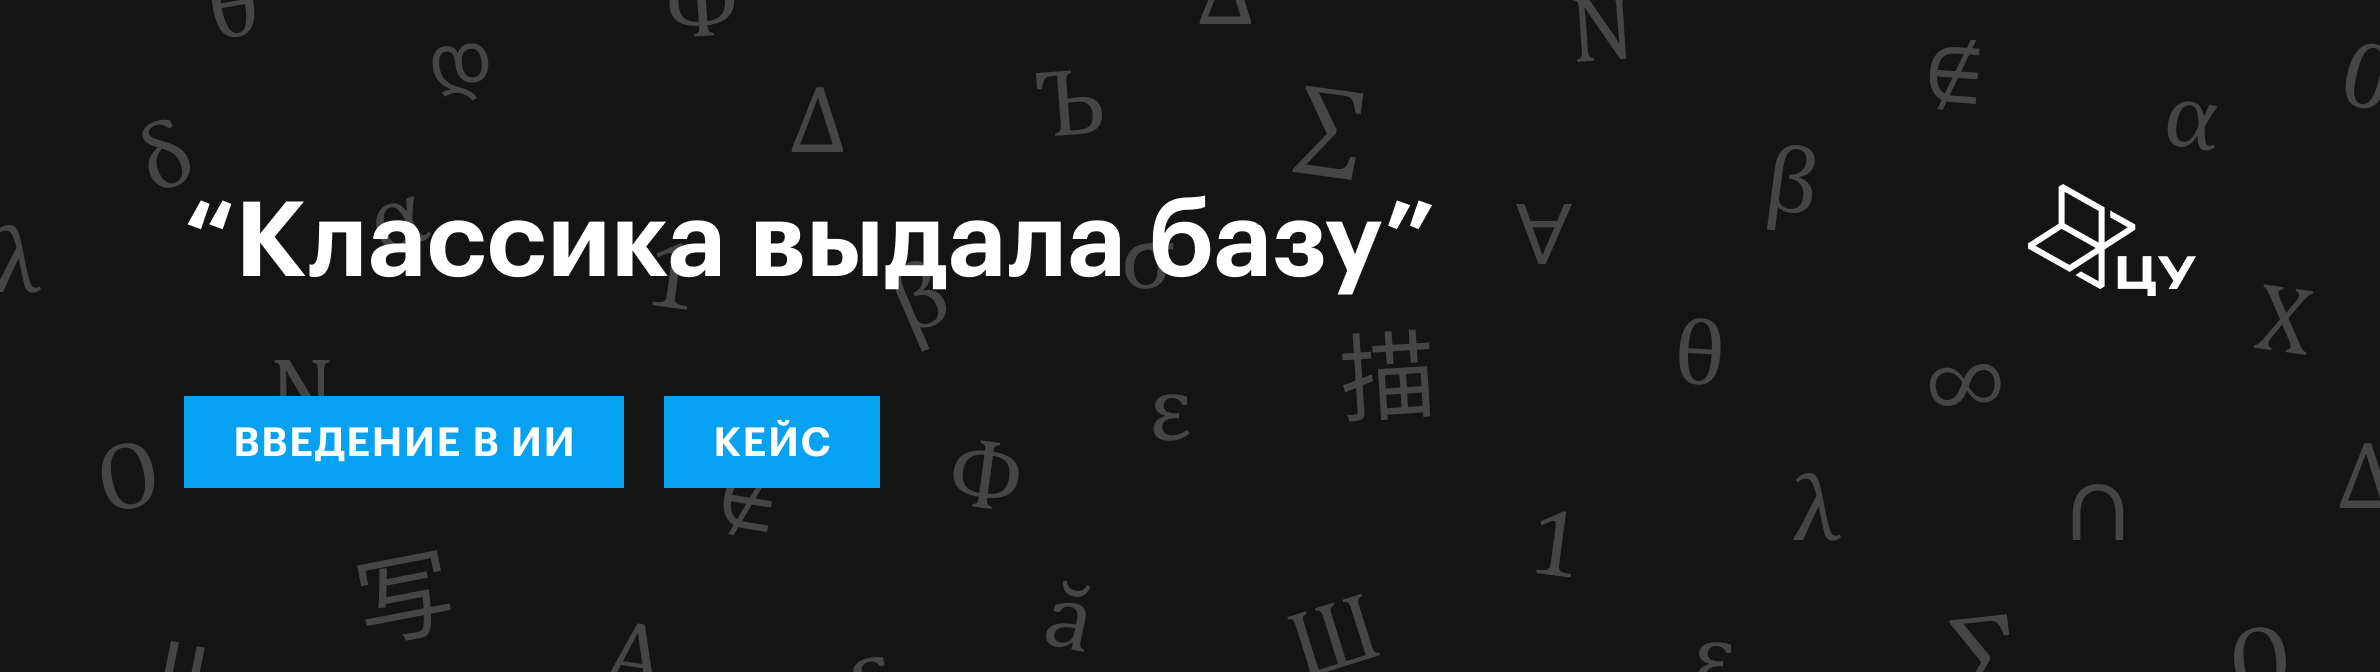

## Легенда

Представьте, что вы устроились NLP-инженером в образовательный EdTech-стартап. Маркетологи компании выяснили, что современные школьники тяжело воспринимают язык классической литературы XIX века.(Также в компанию наняли инженера, который смог встроить в каждую электронную книжкуу по экрану с Subway Surfers, чтобы ученикам было привычнее) Обилие устаревших слов, французских вставок и сложных деепричастных оборотов заставляет их «скипать» чтение.

Стартап решил запустить революционное приложение, которое будет «на лету» переводить тексты Толстого, Достоевского и Гоголя на современный интернет-сленг*.

Ваша задача: разработать нейросетевую Seq2Seq-модель, которая осуществляет перенос стиля (Text Style Transfer). Модель должна брать оригинальную реплику из классики и переписывать ее зумерским сленгом, максимально сохраняя смысл и изначальную структуру предложения.

*Примечение от автора кейса: данные по сленгу собирались из открытых источников: статей в интернете, рилсам, шортсам и тикитокам.*

## Требования к решению

Поскольку это учебный проект, вводятся следующие технические ограничения:

* **Запрет на API-читерство:** Запрещено просто прогнать тестовый датасет через API умных ЛЛМок. Вы должны самостоятельно обучить модель. *При этом, если вам хочется использовать API LLM-сервисов для обогащения датасета, аугментаций и уточнения перевода, то это не запрещено.*

* **Ограничение по размеру модели:** Решение должно корректно работать в Google Colab. Использовать несколько Google-аккаунтов для увеличения квоты на Т4 для экспериментов с архитектурой не запрещено

* **Воспроизводимость:** Весь код должен выполняться последовательно с первого раза. Обязательно фиксируйте random_seed, а также сохраняйте веса моделей и логируйте эксперимент.

**Необходимые этапы решения:**

1. Работа с датасетом. Посмотреть на статистику встречаемости слов и провести предобработку. Определиться с токенизатором и предложить простой бейзлайн.


2. Подбор архитектуры модели. Написание необходимых функций для работы с данной архитектурой. (Например, обрезка текста до 128 символов, для моделей с маленьким контекстным окном)


3. Обучение модели на датасете. Валидация метрик, подбор гиперпарметров генерации. Вспомогательные функции для генерации перевода для новых предложений (тут можно сделать функцию `def translate(text)`, которая занимается переводом текста)

**Проверяемые метрики:**

Оценка качества генерации текста — сложная задача. Мы будем использовать две метрики и смотреть на Loss модели:

*  Обучение (Train/Val Loss): Cross-Entropy Loss. Функция потерь, по которой модель обновляет веса. Желательно избежать переобучения и достичь результатов по Loss меньше ~1.5-2.0

* Главная бизнес-метрика: chrF (Character n-gram F-score). Оценивает совпадение сгенерированного текста с эталоном на уровне символов. Она идеально подходит для сленга, так как прощает ошибки в окончаниях (например, если модель выдала «кринж» вместо «кринжово»).

*  Вспомогательная метрика: BLEU-score. Классическая метрика машинного перевода. Посчитайте её для сравнения с chrF. Данная метрика легко считается и является бейзлайн-метрикой для любой задачи перевода.





## Система оценивания

Решение оценивается по трём параметрам
* **Работа с данными [4 балла]:** Оценка ставится в соответствии с тем, насколько подробно была произведена работа с данными — визуализации, предобработка и очистка/обогащение датасета будут плюсом

* **Решение задачи [4 балла]:** Оценка ставится не за итоговые метрики — для простых моделей их значение может быть небольшим, а за то, насколько качественно были проделаны эксперименты в рамках выбранной модели. То есть если в решении используется примитивная модель, получающая низкие метрики, но она обучена с разными гиперпараметрами и приёмами так, что из её качества выжимается максимум, это решение будет оценено в полный балл

* **Оформление [2 балла]:** Хочется, чтобы написанный код читался, как хорошая книга. Для этого мы добавляем баллы за оформление — они выше, если в коде появляются визуализации, комментарии к коду и сопроводительный текст, и ниже за их отсутствие

## Данные

Итоговый датасет содержит 2 колонки: chunk и translate. В столбце chunk находится кусочек текста из классики. А в столбце translate – соответствующий ему перевод.


В данном датасете вы можете найти отрывки из следующих книг / сборников / произведений:

* А. П. Чехов — Собрание сочинений (рассказы и пьесы)

* А. С. Пушкин — повесть «Пиковая дама»

* И. С. Тургенев — роман «Отцы и дети»

* М. Ю. Лермонтов — роман «Герой нашего времени»

* Н. В. Гоголь — комедия «Ревизор»

* Н. В. Гоголь — поэма «Мёртвые души»

* А. Н. Островский — Собрание пьес (включая драму «Гроза»)

* Л. Н. Толстой — роман-эпопея «Война и мир»

* Ф. М. Достоевский — роман «Братья Карамазовы»



Для подбора метода, желательно подробно исследовать датасет – можно начать с простого просмотра перевода, а закончить построение векторных представлений слов. *Главное помните, EDA должен привести вас к пониманию решения проблемы*

Ссылка на датасет: https://drive.google.com/file/d/1wn6jpF5-FeaZIo2oqSspSvbfjIiVa8F7/view

## Пояснение метрик



**BLEU-score** (Bilingual Evaluation Understudy)
Метрика основана на совпадении целых слов (униграмм) и их комбинаций (n-грамм: биграмм, триграмм и т.д.). Итоговый BLEU считается как геометрическое среднее точностей n-грамм, умноженное на штраф за краткость.

Формула:
$BLEU = BP \cdot \exp\left( \sum_{n=1}^{N} w_n \log p_n \right)$

Где:

$p_n$ — точность совпадения n-грамм (доля n-грамм из генерации, которые нашлись в эталоне).

$w_n$ — вес для $n$-граммы (обычно берут равномерные веса, например, для BLEU-4: $w_n = 0.25$).

$N$ — максимальная длина n-граммы (стандарт — 4).

$BP$ (Brevity Penalty) — штраф за краткость. Запрещает модели читерить, выдавая по одному правильному слову.

Формула штрафа за краткость ($BP$):
BP = \begin{cases} 1, & \text{если } c > r \\ \exp\left(1 - \frac{r}{c}\right), & \text{если } c \le r \end{cases}
Где $c$ — длина сгенерированного текста (candidate), $r$ — длина эталона (reference).



**chrF** (Character n-gram F-score)
В отличие от BLEU, chrF разбивает текст не на слова, а на символьные подстроки (от 1 до 6 символов) и считает по ним классическую F-меру.

Сначала считаются Precision и Recall для совпавших символьных кусочков:

$Precision (P) = \frac{\text{Кол-во совпавших символьных n-грамм}}{\text{Общее кол-во символьных n-грамм в генерации}}$


$Recall (R) = \frac{\text{Кол-во совпавших символьных n-грамм}}{\text{Общее кол-во символьных n-грамм в эталоне}}$

Затем вычисляется итоговая формула chrF (это стандартная $F_\beta$-мера):

$chrF = (1 + \beta^2) \frac{P \cdot R}{\beta^2 \cdot P + R}$

Где:

$\beta$ — параметр, определяющий баланс между точностью и полнотой.

В стандартной реализации (chrF2) используют $\beta = 2$, что дает больший вес Recall (полноте) — то есть алгоритму важнее, чтобы модель не потеряла смысл оригинала, даже если она добавила от себя лишние символы.

### Пример работы метрик

**Оригинал:** "Это было ужасно"

**Эталон**: "это было кринжово"

**Сгенерировано моделью:** "это был кринж"

----



BLEU разбивает текст по пробелам:

Слова эталона: ["это", "было", "кринжово"]

Слова модели: ["это", "был", "кринж"]

Для BLEU слова "было" и "был", а также "кринжово" и "кринж" — это абсолютно разные, никак не связанные слова (как "собака" и "самолет"). Совпало только одно слово: "это".


Шаг 1: Считаем совпадения (Precision для n-грамм)

1-граммы (отдельные слова): Из 3 сгенерированных слов в эталоне есть только одно — "это". $p_1 = 1 / 3 \approx 0.33$ (33%).

2-граммы (пары слов):
Пары модели: ["это был", "был кринж"].
Пары эталона: ["это было", "было кринжово"].
Совпадений нет! Точность $p_2 = 0 / 2 = 0$.

Шаг 2: Штраф за краткость (Brevity Penalty)
Длина генерации ($c=3$) равна длине эталона ($r=3$), поэтому модель не штрафуется за обрывание текста. $BP = 1$

Шаг 3: Итоговая формула BLEU

$$BLEU = BP \cdot \exp\left( \frac{1}{2} \log p_1 + \frac{1}{2} \log p_2 \right)$$

Так как точность биграмм $p_2 = 0$, логарифм нуля уходит в минус бесконечность, и весь BLEU обнуляется.

$$BLEU = 0$$

- - -

chrF нарезает текст на куски (например, по 4 символа, включая пробелы):

Куски эталона (14 штук):
"это_", "то_б", "о_бы", "_был", "было", "ыло_", "ло_к", "о_кр", "_кри", "крин", "ринж", "инжо", "нжов", "жово"

Куски модели (10 штук):
"это_", "то_б", "о_бы", "_был", "был_", "ыл_к", "л_кр", "_кри", "крин", "ринж"

Шаг 1: Ищем совпадения
Алгоритм сравнивает два списка и находит 7 идеальных совпадений:
"это_", "то_б", "о_бы", "_был", "_кри", "крин", "ринж". Корень слова и начало предложения схвачены верно!

Алгоритм видит, что куски "это ", "то б", " был", " кри", "крин", "ринж" совпали


Шаг 2: Считаем Точность (Precision) и Полноту (Recall)

Precision ($P$): Доля правильных кусков среди всех сгенерированных.
$P = 7 / 10 = 0.70$ (70% того, что выдала модель — верно).

Recall ($R$): Доля кусков эталона, которые смогла покрыть модель.
$R = 7 / 14 = 0.50$ (Модель восстановила 50% от оригинальной строки).

Шаг 3: Итоговая формула (F2-score)
chrF по умолчанию использует $\beta = 2$, что дает Полноте в 2 раза больший вес, чем Точности (важнее не потерять смысл, чем не наделать опечаток).

$$chrF = 5 \frac{P \cdot R}{4p+R}$$

Подставляем наши числа и получаем ответ:

$$chrF = 5 \frac{0.7 \cdot 0.5}{4\cdot 0.7 + 0.5} \approx 0.53$$

### Код метрик

Ниже уже реализованы функции подсчёта метрик. Тебе необходимо лишь использовать их

In [ ]:
import math
from collections import Counter

def get_word_ngrams(tokens: list, n: int) -> list:
    """
    Разбивает список токенов на n-граммы уровня слов.
    """
    return [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]


def get_char_ngrams(text: str, n: int) -> list:
    """
    Разбивает строку на n-граммы уровня символов.
    """
    return [text[i : i + n] for i in range(len(text) - n + 1)]


Покажем как работает базовое разбиение на n-граммы: посимвольные и по-"подсловные".

In [ ]:
get_word_ngrams(["я", "тебя", "крашу", "чееел"], 2)

In [ ]:
get_char_ngrams("кринж", 3)

Вычислим теперь наши метрики для двух наших текстов

In [ ]:
def bleu_single(reference: str, candidate: str, max_n: int = 4) -> float:
    """
    Вычисляет BLEU-score для одной пары (reference, candidate).
    Шаги:
      1. Токенизация — разбиение по пробелам
      2. Clipped precision — для каждого n считаем долю n-грамм генерации,
         которые есть в эталоне; одна n-грамма эталона не засчитывается дважды
      3. Add-1 сглаживание — (matches + 1) / (total + 1), чтобы избежать log(0)
         при нулевых совпадениях в высших n-граммах
      4. Brevity Penalty — штраф exp(1 - r/c), если генерация короче эталона

    Args:
        reference : эталонный текст (строка)
        candidate : сгенерированный текст (строка)
        max_n     : максимальный порядок n-граммы (по умолчанию 4 → BLEU-4)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    ref_tokens  = reference.lower().split()
    cand_tokens = candidate.lower().split()

    c = len(cand_tokens)
    r = len(ref_tokens)

    if c == 0:
        return 0.0

    # Штрафуем только за генерацию короче эталона; длиннее — штрафа нет
    bp  = 1.0 if c > r else math.exp(1 - r / c)
    w_n = 1.0 / max_n
    log_avg = 0.0

    for n in range(1, max_n + 1):
        ref_ngrams  = Counter(get_word_ngrams(ref_tokens, n))
        cand_ngrams = Counter(get_word_ngrams(cand_tokens, n))

        # Clipped: не даём модели накручивать счёт повторами одной n-граммы
        matches = sum(min(cnt, ref_ngrams[ngram]) for ngram, cnt in cand_ngrams.items())
        total   = max(c - n + 1, 1)  # floor=1, если предложение короче n

        # Нет совпадений даже на уровне слов — тексты семантически разные
        if n == 1 and matches == 0:
            return 0.0

        p_n      = (matches + 1) / (total + 1)
        log_avg += w_n * math.log(p_n)

    return bp * math.exp(log_avg)


def chrf_single(reference: str, candidate: str, max_n: int = 6, beta: float = 2.0) -> float:
    """
    Вычисляет chrF-score для одной пары (reference, candidate).

    Шаги:
      1. Разбить оба текста на символьные n-граммы (для n от 1 до max_n)
      2. Для каждого n посчитать Precision и Recall по совпавшим кускам
      3. Усреднить Precision и Recall по всем n
      4. Итог: F_beta-мера из усредненных P и R

    Args:
        reference  : эталонный текст (строка)
        candidate  : сгенерированный текст (строка)
        max_n      : максимальный порядок символьной n-граммы (по умолчанию 6)
        beta       : вес Recall относительно Precision (по умолчанию 2.0 -> chrF2)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    if len(candidate) == 0 or len(reference) == 0:
        return 0.0

    total_precision = 0.0
    total_recall    = 0.0

    for n in range(1, max_n + 1):
        ref_ngrams  = Counter(get_char_ngrams(reference, n))
        cand_ngrams = Counter(get_char_ngrams(candidate, n))

        # Считаем совпавшие символьные куски
        matches = sum(
            min(count, ref_ngrams.get(ngram, 0))
            for ngram, count in cand_ngrams.items()
        )

        total_cand = sum(cand_ngrams.values())  # знаменатель Precision
        total_ref  = sum(ref_ngrams.values())   # знаменатель Recall

        if total_cand > 0:
            total_precision += (matches + 1)/ (total_cand + 1)
        if total_ref > 0:
            total_recall += matches / total_ref

    # Усредняем Precision и Recall по всем порядкам n
    avg_p = total_precision / max_n
    avg_r = total_recall    / max_n

    if avg_p + avg_r == 0:
        return 0.0

    # считаем f-бета меру
    chrf = (1 + beta**2) * (avg_p * avg_r) / (beta**2 * avg_p + avg_r)
    return chrf




А теперь с помощью функций выше напишем вычисление метрик для массива текстов. Мы используем такой же интерфейс как у `sci-kit-learn`, где есть необходимо передать `y_true` и `y_pred`

In [ ]:
def compute_bleu(y_true: list, y_pred: list, max_n: int = 4) -> float:
    """Считает средний BLEU по всем парам датасета."""
    scores = [bleu_single(ref, cand, max_n) for ref, cand in zip(y_true, y_pred)]
    return sum(scores) / len(scores)


def compute_chrf(y_true: list, y_pred: list, max_n: int = 6, beta: float = 2.0) -> float:
    """Считает средний chrF по всем парам датасета."""
    scores = [chrf_single(ref, cand, max_n, beta) for ref, cand in zip(y_true, y_pred)]
    return sum(scores) / len(scores)


А здесь мы посмотрим на примеры работы этих метрик с помощью assert-ов

In [ ]:

# ──────────────── ТЕСТ 1 ────────────────
# Идеальное совпадение: предсказание == эталон
# Ожидание: BLEU = 1.0, chrF = 1.0
ref = "этот анк выдал жесткую базу"
assert bleu_single(ref, ref) == 1.0, \
    "ТЕСТ 1 BLEU: При идеальном совпадении BLEU должен быть 1.0"
assert abs(chrf_single(ref, ref) - 1.0) < 1e-9, \
    " ТЕСТ 1 chrF: При идеальном совпадении chrF должен быть 1.0"
print("Тест 1 пройден: Идеальное совпадение → BLEU=1.0, chrF=1.0")

# ──────────────── ТЕСТ 2 ────────────────
# Пустая генерация: candidate = ""
# Ожидание: BLEU = 0.0, chrF = 0.0
ref = "он буквально вкрашился в неё"
assert bleu_single(ref, "") == 0.0, \
    " ТЕСТ 2 BLEU: Пустая генерация должна давать 0.0"
assert chrf_single(ref, "") == 0.0, \
    " ТЕСТ 2 chrF: Пустая генерация должна давать 0.0"
print("Тест 2 пройден: Пустая генерация → BLEU=0.0, chrF=0.0")

# ──────────────── ТЕСТ 3 ────────────────
# Полностью разные тексты
# Ожидание: BLEU = 0.0, chrF близко к 0
ref  = "служить бы рад прислуживаться тошно"
cand = "икс игрек зет фу бар"
assert bleu_single(ref, cand) == 0.0, \
    " ТЕСТ 3 BLEU: Полностью разные тексты → BLEU должен быть 0.0"
assert chrf_single(ref, cand) < 0.1, \
    " ТЕСТ 3 chrF: Полностью разные тексты → chrF должен быть близок к 0"
print(" Тест 3 пройден: Полностью разные тексты → BLEU=0.0, chrF≈0")

# ──────────────── ТЕСТ 4 ────────────────
# Ключевой тест: chrF > BLEU при морфологическом совпадении
# "кринж" vs "кринжово" — разные слова для BLEU, но похожие символьно для chrF
ref  = "это было кринжово"
cand = "это было кринж"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert chrf_score > bleu_score, \
    f" ТЕСТ 4: chrF ({chrf_score:.3f}) должен быть > BLEU ({bleu_score:.3f}) при морфологических различиях!"
print(f" Тест 4 пройден: chrF ({chrf_score:.3f}) > BLEU ({bleu_score:.3f}) — chrF лучше для русской морфологии!")

# ──────────────── ТЕСТ 5 ────────────────
# Частичное совпадение: значения должны быть строго в диапазоне (0, 1)
ref  = "базаров выдал жесткую базу и ливнул"
cand = "базаров выдал базу и просто ушел"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert 0.0 < bleu_score < 1.0, \
    f" ТЕСТ 5 BLEU: При частичном совпадении BLEU должен быть в (0, 1), получили {bleu_score:.3f}"
assert 0.0 < chrf_score < 1.0, \
    f" ТЕСТ 5 chrF: При частичном совпадении chrF должен быть в (0, 1), получили {chrf_score:.3f}"
print(f" Тест 5 пройден: Частичное совпадение → BLEU={bleu_score:.3f}, chrF={chrf_score:.3f}")

# ──────────────── ТЕСТ 6 ────────────────
# Тест усреднения по датасету
y_true = ["этот скуф выдал базу",     "она ливнула с вписки"]
y_pred = ["этот скуф выдал базу",     "она ливнула с вписки"]  # идеальные предсказания
assert compute_bleu(y_true, y_pred) == 1.0, \
    " ТЕСТ 6 BLEU: Усредненный BLEU по идеальным парам должен быть 1.0"
assert abs(compute_chrf(y_true, y_pred) - 1.0) < 1e-9, \
    " ТЕСТ 6 chrF: Усредненный chrF по идеальным парам должен быть 1.0"
print(" Тест 6 пройден: Усреднение по датасету работает корректно!")


## Пример работы метрик

**Оригинал:** "Это было ужасно".

**Эталон**: "это было кринжово"

**Сгенерировано моделью:** "это был кринж"




----



BLEU разбивает текст по пробелам:

Слова эталона: ["это", "было", "кринжово"]

Слова модели: ["это", "был", "кринж"]

Для BLEU слова "было" и "был", а также "кринжово" и "кринж" — это абсолютно разные, никак не связанные слова (как "собака" и "самолет"). Совпало только одно слово: "это".


Шаг 1: Считаем совпадения (Precision для n-грамм)

1-граммы (отдельные слова): Из 3 сгенерированных слов в эталоне есть только одно — "это". $p_1 = 1 / 3 \approx 0.33$ (33%).

2-граммы (пары слов):
Пары модели: ["это был", "был кринж"].
Пары эталона: ["это было", "было кринжово"].
Совпадений нет! Точность $p_2 = 0 / 2 = 0$.

Шаг 2: Штраф за краткость (Brevity Penalty)
Длина генерации ($c=3$) равна длине эталона ($r=3$), поэтому модель не штрафуется за обрывание текста. $BP = 1$

Шаг 3: Итоговая формула BLEU

$$BLEU = BP \cdot \exp\left( \frac{1}{2} \log p_1 + \frac{1}{2} \log p_2 \right)$$

Так как точность биграмм $p_2 = 0$, логарифм нуля уходит в минус бесконечность, и весь BLEU обнуляется.

$$BLEU = 0$$

- - -

chrF нарезает текст на куски (например, по 4 символа, включая пробелы):

Куски эталона (14 штук):
"это_", "то_б", "о_бы", "_был", "было", "ыло_", "ло_к", "о_кр", "_кри", "крин", "ринж", "инжо", "нжов", "жово"

Куски модели (10 штук):
"это_", "то_б", "о_бы", "_был", "был_", "ыл_к", "л_кр", "_кри", "крин", "ринж"

Шаг 1: Ищем совпадения
Алгоритм сравнивает два списка и находит 7 идеальных совпадений:
"это_", "то_б", "о_бы", "_был", "_кри", "крин", "ринж". Корень слова и начало предложения схвачены верно!

Алгоритм видит, что куски "это ", "то б", " был", " кри", "крин", "ринж" совпали


Шаг 2: Считаем Точность (Precision) и Полноту (Recall)

Precision ($P$): Доля правильных кусков среди всех сгенерированных.
$P = 7 / 10 = 0.70$ (70% того, что выдала модель — верно).

Recall ($R$): Доля кусков эталона, которые смогла покрыть модель.
$R = 7 / 14 = 0.50$ (Модель восстановила 50% от оригинальной строки).

Шаг 3: Итоговая формула (F2-score)
chrF по умолчанию использует $\beta = 2$, что дает Полноте в 2 раза больший вес, чем Точности (важнее не потерять смысл, чем не наделать опечаток).

$$chrF = 5 \frac{P \cdot R}{4p+R}$$

Подставляем наши числа и получаем ответ:

$$chrF = 5 \frac{0.7 \cdot 0.5}{4\cdot 0.7 + 0.5} \approx 0.53$$

Здесь вам надо будет реализовать функции подсчета метрик для двух текстов

In [ ]:
!pip install sacrebleu

In [ ]:
import sacrebleu

def bleu_single(reference: str, candidate: str, max_n: int = 4) -> float:
    """
    BLEU для одной пары (sentence-level) через sacrebleu.
    Возвращает значение в диапазоне [0, 1].
    """
    if not candidate.strip():
        return 0.0

    bleu = sacrebleu.sentence_bleu(
        candidate,
        [reference],
        smooth_method="none",
        use_effective_order=False
    )
    return bleu.score / 100.0


def chrf_single(reference: str, candidate: str, max_n: int = 6, beta: float = 2.0) -> float:
    """
    chrF для одной пары (sentence-level) через sacrebleu.
    Возвращает значение в диапазоне [0, 1].
    """
    if not candidate.strip():
        return 0.0

    chrf = sacrebleu.sentence_chrf(
        candidate,
        [reference],
        char_order=4,
        beta=beta
    )
    return chrf.score / 100.0


def compute_bleu(y_true: list, y_pred: list, max_n: int = 4) -> float:
    """
    Corpus-level BLEU через sacrebleu (корректный стандартный способ).
    Возвращает значение в диапазоне [0, 1].
    """
    if not y_true:
        return 0.0

    bleu = sacrebleu.corpus_bleu(
        y_pred,
        [y_true],
        smooth_method="none",
        use_effective_order=False
    )
    return bleu.score / 100.0


def compute_chrf(y_true: list, y_pred: list, max_n: int = 6, beta: float = 2.0) -> float:
    """
    Corpus-level chrF через sacrebleu.
    Возвращает значение в диапазоне [0, 1].
    """
    if not y_true:
        return 0.0

    chrf = sacrebleu.corpus_chrf(
        y_pred,
        [y_true],
        char_order=max_n,
        beta=beta
    )
    return chrf.score / 100.0

In [ ]:
bleu_single("это было кринжово", "это было кринж")
chrf_single("это было кринжово", "это было кринж")

In [ ]:
def bleu_single(reference: str, candidate: str, max_n: int = 4) -> float:
    """
    Вычисляет BLEU-score для одной пары (reference, candidate).

    Шаги:
      1. Токенизация (разбиение по пробелам)
      2. Подсчет clipped n-gram precision p_n для каждого n
      3. Вычисление штрафа за краткость BP
      4. Итог: BP * exp(sum(w_n * log(p_n)))

    Args:
        reference  : эталонный текст (строка)
        candidate  : сгенерированный текст (строка)
        max_n      : максимальный порядок n-граммы (по умолчанию 4 → BLEU-4)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    ref_tokens = reference.lower().split()
    cand_tokens = candidate.lower().split()
    c, r = len(cand_tokens), len(ref_tokens)
    if c == 0 or r == 0:
        return 0.0

    # Штраф только за генерацию короче эталона
    bp = 1.0 if c > r else math.exp(1 - r / c)
    log_avg = 0.0
    for n in range(1, max_n + 1):
        ref_ngrams = Counter(get_word_ngrams(ref_tokens, n))
        cand_ngrams = Counter(get_word_ngrams(cand_tokens, n))
        # Clipped precision: n-грамма засчитывается не больше раз, чем встречается в эталоне
        matches = sum(min(cnt, ref_ngrams[ng]) for ng, cnt in cand_ngrams.items())
        total = max(c - n + 1, 1)
        # Ни одного общего слова — тексты разные, BLEU = 0
        if n == 1 and matches == 0:
            return 0.0
        # Add-1 сглаживание: без него короткие предложения почти всегда получают 0
        p_n = (matches + 1) / (total + 1)
        log_avg += math.log(p_n) / max_n
    return bp * math.exp(log_avg)


def chrf_single(reference: str, candidate: str, max_n: int = 6, beta: float = 2.0) -> float:
    """
    Вычисляет chrF-score для одной пары (reference, candidate).

    Шаги:
      1. Разбить оба текста на символьные n-граммы (для n от 1 до max_n)
      2. Для каждого n посчитать Precision и Recall по совпавшим кускам
      3. Усреднить Precision и Recall по всем n
      4. Итог: F_beta-мера из усредненных P и R

    Args:
        reference  : эталонный текст (строка)
        candidate  : сгенерированный текст (строка)
        max_n      : максимальный порядок символьной n-граммы (по умолчанию 6)
        beta       : вес Recall относительно Precision (по умолчанию 2.0 → chrF2)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    if not candidate or not reference:
        return 0.0

    total_p, total_r = 0.0, 0.0
    for n in range(1, max_n + 1):
        ref_ngrams = Counter(get_char_ngrams(reference, n))
        cand_ngrams = Counter(get_char_ngrams(candidate, n))
        matches = sum(min(cnt, ref_ngrams.get(ng, 0)) for ng, cnt in cand_ngrams.items())
        total_cand = sum(cand_ngrams.values())
        total_ref = sum(ref_ngrams.values())
        if total_cand > 0:
            total_p += (matches + 1) / (total_cand + 1)  # сглаживание, как в эталонной версии
        if total_ref > 0:
            total_r += matches / total_ref

    avg_p, avg_r = total_p / max_n, total_r / max_n
    if avg_p + avg_r == 0:
        return 0.0
    return (1 + beta**2) * avg_p * avg_r / (beta**2 * avg_p + avg_r)

In [ ]:
def compute_bleu(y_true: list, y_pred: list, max_n: int = 4) -> float:
    """Считает средний BLEU по всем парам датасета."""
    if not y_true:
        return 0.0
    return sum(bleu_single(ref, cand, max_n) for ref, cand in zip(y_true, y_pred)) / len(y_true)


def compute_chrf(y_true: list, y_pred: list, max_n: int = 6, beta: float = 2.0) -> float:
    """Считает средний chrF по всем парам датасета."""
    if not y_true:
        return 0.0
    return sum(chrf_single(ref, cand, max_n, beta) for ref, cand in zip(y_true, y_pred)) / len(y_true)

Тесты. Их необходимо запустить, и если они сработают верно – продолжать дальше

In [ ]:
# ──────────────── ТЕСТ 1 ────────────────
ref = "этот анк выдал жесткую базу"
assert bleu_single(ref, ref) == 1.0, \
    "❌ ТЕСТ 1 BLEU: При идеальном совпадении BLEU должен быть 1.0"
assert abs(chrf_single(ref, ref) - 1.0) < 1e-9, \
    "❌ ТЕСТ 1 chrF: При идеальном совпадении chrF должен быть 1.0"
print("✅ Тест 1 пройден")

# ──────────────── ТЕСТ 2 ────────────────
ref = "он буквально вкрашился в неё"
assert bleu_single(ref, "") == 0.0, \
    "❌ ТЕСТ 2 BLEU: Пустая генерация должна давать 0.0"
assert chrf_single(ref, "") == 0.0, \
    "❌ ТЕСТ 2 chrF: Пустая генерация должна давать 0.0"
print("✅ Тест 2 пройден")

# ──────────────── ТЕСТ 3 ────────────────
ref  = "служить бы рад прислуживаться тошно"
cand = "икс игрек зет фу бар"
assert bleu_single(ref, cand) == 0.0, \
    "❌ ТЕСТ 3 BLEU: Полностью разные тексты => BLEU должен быть 0.0"
assert chrf_single(ref, cand) < 0.1, \
    "❌ ТЕСТ 3 chrF: Полностью разные тексты => chrF должен быть близок к 0"
print("✅ Тест 3 пройден")

# ──────────────── ТЕСТ 4 ────────────────
ref  = "это было кринжово"
cand = "это было кринж"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert chrf_score > bleu_score, \
    f"❌ ТЕСТ 4: chrF ({chrf_score:.3f}) должен быть > BLEU ({bleu_score:.3f}) при морфологических различиях!"
print(f"✅ Тест 4 пройден")

# ──────────────── ТЕСТ 5 ────────────────
ref  = "базаров выдал жесткую базу и ливнул"
cand = "базаров выдал базу и просто ушел"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert 0.0 < bleu_score < 1.0, \
    f"❌ ТЕСТ 5 BLEU: При частичном совпадении BLEU должен быть в (0, 1), получили {bleu_score:.3f}"
assert 0.0 < chrf_score < 1.0, \
    f"❌ ТЕСТ 5 chrF: При частичном совпадении chrF должен быть в (0, 1), получили {chrf_score:.3f}"
print(f"✅ Тест 5 пройден")

# ──────────────── ТЕСТ 6 ────────────────
y_true = ["этот скуф выдал базу",     "она ливнула с вписки"]
y_pred = ["этот скуф выдал базу",     "она ливнула с вписки"]  #
assert compute_bleu(y_true, y_pred) == 1.0, \
    "❌ ТЕСТ 6 BLEU: Усредненный BLEU по идеальным парам должен быть 1.0"
assert abs(compute_chrf(y_true, y_pred) - 1.0) < 1e-9, \
    "❌ ТЕСТ 6 chrF: Усредненный chrF по идеальным парам должен быть 1.0"
print("✅ Тест 6 пройден")

print("\n🎉 Все 6 тестов пройдены! Ваши реализации метрик корректны.")

## Твой код

### План решения

1. **EDA.** Длины текстов, два режима перевода (точечная замена слов и полный пересказ), шум в данных, частотный «сленговый словарь».
2. **Предобработка.** Чистка, нижний регистр, выравнивание предложений оригинала и перевода динамическим программированием, нарезка на короткие пары ≤ 200 символов. Длинные куски по 2–3 тысячи символов не влезают в контекст модели, а короткие выровненные пары — влезают.
3. **Токенизатор и бейзлайны.** SentencePiece-токенизатор ruT5, выбор `MAX_LEN`. Бейзлайны: копирование входа и словарная замена слов.
4. **Модель.** Дообучение предобученной ruT5 (encoder-decoder). Эксперименты: размер модели и learning rate, затем финальное обучение с early stopping.
5. **Генерация.** Подбор гиперпараметров декодирования (greedy, beam search, запрет повторов, сэмплирование).
6. **Анализ ошибок и итог.** Метрики на отложенной выборке по режимам, функция `translate`.

Весь ноутбук рассчитан на Google Colab с GPU T4: полный прогон занимает около часа. Флаг `SMOKE` (переменная окружения `NLP_CASE_SMOKE=1`) включает быстрый прогон на крошечной подвыборке: он нужен только для проверки, что код выполняется от начала до конца.

In [ ]:
%pip install -q transformers sentencepiece gdown

In [ ]:
import os
import re
import json
import time
import math
import random
import difflib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

SEED = 42
SMOKE = os.environ.get("NLP_CASE_SMOKE") == "1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "nlp_case_runs"  # логи экспериментов и веса моделей
os.makedirs(OUT_DIR, exist_ok=True)


def set_seed(seed: int = SEED) -> None:
    """Фиксирует все источники случайности для воспроизводимости."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
sns.set_theme(style="whitegrid")
print(f"device: {DEVICE}, smoke-прогон: {SMOKE}")

## 1. Данные и EDA

In [ ]:
DATA_PATH = "nlp_case_dataset.csv"
if not os.path.exists(DATA_PATH):
    import gdown
    gdown.download(id="1wn6jpF5-FeaZIo2oqSspSvbfjIiVa8F7", output=DATA_PATH, quiet=True)

raw = pd.read_csv(DATA_PATH)
print("Размер:", raw.shape)
print("Пропуски:\n", raw.isna().sum())
print("Полных дубликатов:", raw.duplicated().sum())

# Пустой перевод учить нельзя: удаляем такие строки
data = raw.dropna().drop_duplicates().reset_index(drop=True)
data["chunk_id"] = data.index
if SMOKE:
    data = data.sample(60, random_state=SEED).reset_index(drop=True)
print("После очистки:", data.shape)

In [ ]:
data["src_chars"] = data.chunk.str.len()
data["tgt_chars"] = data.translate.str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data[["src_chars", "tgt_chars"]].rename(columns={"src_chars": "оригинал", "tgt_chars": "перевод"}),
             bins=60, element="step", ax=axes[0])
axes[0].set(title="Длина фрагментов, символов", xlabel="символов", xlim=(0, 6000))
axes[1].scatter(data.src_chars, data.tgt_chars, s=4, alpha=0.4)
axes[1].plot([0, 6000], [0, 6000], "r--", lw=1)
axes[1].set(title="Длина перевода vs длина оригинала", xlabel="оригинал", ylabel="перевод", xlim=(0, 6000), ylim=(0, 6000))
plt.tight_layout()
plt.show()

data[["src_chars", "tgt_chars"]].describe().round(0)

Фрагменты длинные: медиана около 2 400 символов (≈ 600 токенов). Это больше контекста маленьких seq2seq-моделей, поэтому целиком их подавать нельзя. Длина перевода почти равна длине оригинала: перевод сохраняет структуру текста.

Посмотрим, насколько перевод отличается от оригинала. Для каждой пары считаем долю совпадающих слов (`difflib.SequenceMatcher` по словам).

In [ ]:
def words(text: str) -> list:
    return re.findall(r"\w+", text.lower())


data["word_overlap"] = [
    difflib.SequenceMatcher(None, words(a), words(b), autojunk=False).ratio()
    for a, b in zip(data.chunk, data.translate)
]
REGIME_THRESHOLD = 0.6
data["regime"] = np.where(data.word_overlap >= REGIME_THRESHOLD, "замена слов", "пересказ")

ax = sns.histplot(data.word_overlap, bins=50)
ax.axvline(REGIME_THRESHOLD, color="r", ls="--")
ax.set(title="Доля общих слов у оригинала и перевода", xlabel="SequenceMatcher.ratio по словам")
plt.show()
print(data.regime.value_counts(normalize=True).round(3))

In [ ]:
for regime in ["замена слов", "пересказ"]:
    row = data[data.regime == regime].iloc[0]
    print(f"===== {regime} (overlap={row.word_overlap:.2f}) =====")
    print("ОРИГИНАЛ:", row.chunk[:300].replace("\n", " "))
    print("ПЕРЕВОД: ", row.translate[:300].replace("\n", " "), "\n")

**Вывод:** в данных два разных режима перевода.

* **Замена слов** (~80 % пар): текст почти не меняется, отдельные слова заменены сленгом («мужчина» → «анк», «глупо» → «кринж»).
* **Пересказ** (~20 %): текст полностью переписан, общих слов мало.

Для первого режима сильным бейзлайном будет простое копирование входа. Модель должна научиться в основном копировать текст и точечно вставлять сленг.

Дальше ищем шум: служебные маркеры, неразрывные пробелы, разные тире, регистр.

In [ ]:
noise = pd.DataFrame({
    "маркеры {12345}": [data.chunk.str.contains(r"\{\d+\}").mean(), data.translate.str.contains(r"\{\d+\}").mean()],
    "неразрывный пробел": [data.chunk.str.contains("\xa0").mean(), data.translate.str.contains("\xa0").mean()],
    "короткое тире –": [data.chunk.str.contains("–").mean(), data.translate.str.contains("–").mean()],
    "есть заглавные буквы": [data.chunk.str.contains(r"[А-ЯЁ]").mean(), data.translate.str.contains(r"[А-ЯЁ]").mean()],
    "есть латиница": [data.chunk.str.contains(r"[a-zA-Z]").mean(), data.translate.str.contains(r"[a-zA-Z]").mean()],
}, index=["оригинал", "перевод"]).T
(noise * 100).round(1).astype(str) + " %"

Перевод чаще всего в нижнем регистре, а оригинал — нет. Поэтому приводим к нижнему регистру обе стороны: модель не тратит силы на регистр, а метрики честно сравнивают содержание. Маркеры `{12345}` (номера страниц) и неразрывные пробелы удаляем, тире унифицируем.

### Частотный анализ: какие слова приносит перевод

Сравним частоты слов в оригиналах и переводах. Слова с наибольшим отношением частот — это и есть сленг, которому должна научиться модель.

In [ ]:
src_freq = Counter(w for t in data.chunk for w in words(t))
tgt_freq = Counter(w for t in data.translate for w in words(t))
print(f"Словарь оригинала: {len(src_freq):,} слов, словарь перевода: {len(tgt_freq):,} слов")
print("Самые частые слова перевода:", [w for w, _ in tgt_freq.most_common(15)])

# Логарифм отношения частот со сглаживанием: >0 — слово типично для перевода
min_count = 3 if SMOKE else 30
slang = pd.DataFrame(
    [(w, c, src_freq[w], math.log((c + 1) / (src_freq[w] + 1))) for w, c in tgt_freq.items() if c >= min_count],
    columns=["слово", "в переводе", "в оригинале", "log_ratio"],
).sort_values("log_ratio", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
top = slang.head(30)
ax.barh(top["слово"][::-1], top["в переводе"][::-1])
ax.set(title="30 слов, которые появляются в основном в переводе", xlabel="частота в переводах")
plt.tight_layout()
plt.show()

### Словарь замен

В парах режима «замена слов» выравниваем слова оригинала и перевода и считаем замены вида «одно слово → одно слово». Это показывает, *как* устроен перевод, и даёт словарный бейзлайн.

In [ ]:
def word_replacements(src: str, tgt: str):
    """Пары (слово оригинала, слово перевода) из замен 1:1 по выравниванию difflib."""
    a, b = words(src), words(tgt)
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
        if op == "replace" and i2 - i1 == j2 - j1:
            yield from zip(a[i1:i2], b[j1:j2])


def build_replacement_table(df: pd.DataFrame) -> pd.DataFrame:
    subst = df[df.regime == "замена слов"]
    pair_counts = Counter(p for s, t in zip(subst.chunk, subst.translate) for p in word_replacements(s, t))
    word_counts = Counter(w for s in subst.chunk for w in words(s))
    table = pd.DataFrame([(s, t, c, word_counts[s]) for (s, t), c in pair_counts.items()],
                         columns=["оригинал", "перевод", "замен", "всего"])
    table["доля"] = table["замен"] / table["всего"]
    return table.sort_values("замен", ascending=False).reset_index(drop=True)


replacements_all = build_replacement_table(data)
replacements_all.head(20)

Видно, что замены устойчивые: многие слова почти всегда заменяются одним и тем же сленговым словом. Но много и «шумных» замен из-за морфологии (разные формы одного слова), так что словарь поможет лишь частично.

## 2. Предобработка

### Разбиение на train / val / test

Делим **по исходным фрагментам** до нарезки, иначе предложения одного фрагмента попадут и в обучение, и в тест (утечка). Стратифицируем по режиму перевода.

In [ ]:
from sklearn.model_selection import train_test_split

train_chunks, rest = train_test_split(data, test_size=0.2, random_state=SEED, stratify=data.regime)
val_chunks, test_chunks = train_test_split(rest, test_size=0.5, random_state=SEED, stratify=rest.regime)
split_of = {**{i: "train" for i in train_chunks.chunk_id}, **{i: "val" for i in val_chunks.chunk_id},
            **{i: "test" for i in test_chunks.chunk_id}}
data["split"] = data.chunk_id.map(split_of)
data.groupby(["split", "regime"]).size().unstack()

### Нормализация и выравнивание предложений

Фрагменты надо порезать на короткие пары «оригинал → перевод». Число предложений в оригинале и переводе часто разное (при пересказе предложения сливаются и делятся), поэтому просто резать «по номеру предложения» нельзя.

Используем монотонное выравнивание динамическим программированием (идея алгоритма Gale–Church): разрешены шаги 1-1, 1-2, 2-1, 2-2 и пропуски. Стоимость шага: `1 − сходство` по символьным триграммам + штраф за разницу длин. Затем соседние выровненные пары склеиваются в сегменты до 200 символов.

In [ ]:
MARKER_RE = re.compile(r"\{\d+\}")
DASH_RE = re.compile(r"(^|\s)[–-](?=\s)")
SENT_RE = re.compile(r"(?<=[.!?…])\s+")
SEGMENT_CHARS = 200


def normalize(text: str) -> str:
    """Чистка: маркеры страниц, неразрывные пробелы, тире, переносы строк, нижний регистр."""
    text = MARKER_RE.sub(" ", text)
    text = text.replace("\xa0", " ").replace("–", "—")
    text = DASH_RE.sub(r"\1—", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()


def split_sentences(text: str) -> list:
    return [s for s in SENT_RE.split(text) if s]


def char_profile(text: str, n: int = 3) -> Counter:
    t = f" {text} "
    return Counter(t[i : i + n] for i in range(len(t) - n + 1))


def similarity(a: str, b: str) -> float:
    """Коэффициент Дайса по символьным триграммам: 1 — тексты совпадают, 0 — нет общих триграмм."""
    pa, pb = char_profile(a), char_profile(b)
    total = sum(pa.values()) + sum(pb.values())
    return 2 * sum((pa & pb).values()) / total if total else 0.0


def align_sentences(src: list, tgt: list) -> list:
    """Монотонное выравнивание двух списков предложений. Возвращает пары (src_text, tgt_text).

    Для скорости: профили триграмм кусков из 1–2 предложений считаются один раз,
    а поиск ведётся только в полосе вокруг диагонали (выравнивание почти линейное).
    """
    n, m = len(src), len(tgt)
    steps = [(1, 1), (1, 2), (2, 1), (2, 2), (1, 0), (0, 1)]
    skip_cost = 1.5
    band = max(8, int(0.2 * max(n, m)))

    def spans(sents):
        out = {}
        for i in range(len(sents)):
            for k in (1, 2):
                if i + k <= len(sents):
                    text = " ".join(sents[i : i + k])
                    prof = char_profile(text)
                    out[i, k] = (len(text), prof, sum(prof.values()))
        return out

    src_spans, tgt_spans = spans(src), spans(tgt)
    cost = np.full((n + 1, m + 1), np.inf)
    back = np.zeros((n + 1, m + 1, 2), dtype=int)
    cost[0, 0] = 0.0
    for i in range(n + 1):
        center = i * m / max(n, 1)
        for j in range(max(0, int(center - band)), min(m, int(center + band)) + 1):
            if cost[i, j] == np.inf:
                continue
            for di, dj in steps:
                ni, nj = i + di, j + dj
                if ni > n or nj > m:
                    continue
                if di == 0 or dj == 0:
                    step_cost = skip_cost
                else:
                    ls, ps, ts = src_spans[i, di]
                    lt, pt, tt = tgt_spans[j, dj]
                    sim = 2 * sum((ps & pt).values()) / (ts + tt)
                    length_penalty = abs(math.log((ls + 1) / (lt + 1)))
                    step_cost = (1 - sim) + length_penalty + 0.1 * (di + dj - 2)
                if cost[i, j] + step_cost < cost[ni, nj]:
                    cost[ni, nj] = cost[i, j] + step_cost
                    back[ni, nj] = (di, dj)
    if cost[n, m] == np.inf:  # путь не уложился в полосу: отдаём фрагмент целиком, фильтр длины его отсеет
        return [(" ".join(src), " ".join(tgt))]
    pairs, i, j = [], n, m
    while i > 0 or j > 0:
        di, dj = back[i, j]
        pairs.append((" ".join(src[i - di : i]), " ".join(tgt[j - dj : j])))
        i, j = i - di, j - dj
    return pairs[::-1]


def group_sentences(sentences: list, max_chars: int = SEGMENT_CHARS) -> list:
    """Жадно склеивает соседние предложения в куски не длиннее max_chars."""
    groups, cur = [], []
    for s in sentences:
        if cur and len(" ".join(cur + [s])) > max_chars:
            groups.append(cur)
            cur = []
        cur.append(s)
    if cur:
        groups.append(cur)
    return groups


def make_segments(pairs: list, max_chars: int = SEGMENT_CHARS) -> list:
    """Склеивает выровненные пары в сегменты. Пары с пустой стороной приклеиваются к текущему сегменту."""
    segments, cur_s, cur_t = [], [], []
    for s, t in pairs:
        if cur_s and s and len(" ".join(cur_s + [s])) > max_chars:
            segments.append((" ".join(cur_s), " ".join(cur_t)))
            cur_s, cur_t = [], []
        if s:
            cur_s.append(s)
        if t:
            cur_t.append(t)
    if cur_s and cur_t:
        segments.append((" ".join(cur_s), " ".join(cur_t)))
    return segments


src_sents = split_sentences(normalize(data.chunk[0]))
tgt_sents = split_sentences(normalize(data.translate[0]))
for s, t in make_segments(align_sentences(src_sents, tgt_sents))[:3]:
    print("SRC:", s, "\nTGT:", t, "\n")

In [ ]:
t0 = time.time()
rows = []
for r in data.itertuples():
    pairs = align_sentences(split_sentences(normalize(r.chunk)), split_sentences(normalize(r.translate)))
    for s, t in make_segments(pairs):
        rows.append({"chunk_id": r.chunk_id, "split": r.split, "regime": r.regime, "src": s, "tgt": t})
segments = pd.DataFrame(rows)
segments["sim"] = [similarity(s, t) for s, t in zip(segments.src, segments.tgt)]
segments["len_ratio"] = segments.tgt.str.len() / segments.src.str.len()
print(f"Сегментов: {len(segments):,}, время выравнивания: {time.time() - t0:.0f} c")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=segments, x="sim", hue="regime", bins=50, element="step", ax=axes[0])
axes[0].set(title="Сходство сторон сегмента (триграммы)")
sns.histplot(segments.len_ratio.clip(0, 3), bins=60, ax=axes[1])
axes[1].set(title="Длина перевода / длина оригинала", xlabel="отношение длин")
plt.tight_layout()
plt.show()

Сходство в режиме «замена слов» близко к 1, в режиме «пересказ» — около 0.3–0.5. Это ожидаемо. Сегменты с почти нулевым сходством или длиной, отличающейся в разы, — ошибки выравнивания. Их удаляем, как и слишком длинные сегменты (одно огромное предложение).

In [ ]:
bad = (segments.sim < 0.15) | (segments.len_ratio > 2.5) | (segments.len_ratio < 0.4) | (segments.src.str.len() > 600)
print(f"Удаляем {bad.sum()} сегментов ({bad.mean():.1%})")
print("Пример удалённого:\n", segments[bad].head(2)[["src", "tgt"]].to_string()[:600])
segments = segments[~bad].reset_index(drop=True)

train_df = segments[segments.split == "train"].reset_index(drop=True)
val_df = segments[segments.split == "val"].reset_index(drop=True)
test_df = segments[segments.split == "test"].reset_index(drop=True)
print(f"\ntrain: {len(train_df):,}  val: {len(val_df):,}  test: {len(test_df):,}")
segments.to_csv(os.path.join(OUT_DIR, "segments.csv"), index=False)

## 3. Токенизатор и бейзлайны

### Токенизатор

Берём SentencePiece-токенизатор предобученной русской T5 (`cointegrated/rut5-base`): он обучен на русских текстах и не даёт `<unk>` на сленге — незнакомые слова распадаются на подслова. Проверим это и выберем максимальную длину последовательности.

In [ ]:
MODEL_BASE = "cointegrated/rut5-base"     # 244M параметров
MODEL_SMALL = "cointegrated/rut5-small"   # 65M параметров
MAIN_MODEL = MODEL_SMALL if SMOKE else MODEL_BASE

tokenizer = AutoTokenizer.from_pretrained(MAIN_MODEL)
sample = segments.sample(min(3000, len(segments)), random_state=SEED)
src_ids = tokenizer(sample.src.tolist()).input_ids
tgt_ids = tokenizer(sample.tgt.tolist()).input_ids
src_len = np.array([len(x) for x in src_ids])
tgt_len = np.array([len(x) for x in tgt_ids])
unk_share = np.mean([tok == tokenizer.unk_token_id for ids in tgt_ids for tok in ids])

print("Пример токенизации:", tokenizer.tokenize("чел реально словил кринж и ливнул с вписки"))
print(f"Доля <unk> в переводах: {unk_share:.4%}")
print(f"Символов на токен: {sample.src.str.len().sum() / src_len.sum():.2f}")
for q in [50, 95, 99, 99.9]:
    print(f"{q}-й перцентиль длины, токенов: src={np.percentile(src_len, q):.0f}, tgt={np.percentile(tgt_len, q):.0f}")

MAX_LEN = 128
ax = sns.histplot({"оригинал": src_len, "перевод": tgt_len}, bins=60, element="step")
ax.axvline(MAX_LEN, color="r", ls="--")
ax.set(title="Длина сегментов в токенах", xlabel="токенов")
plt.show()
print(f"Обрезаются при MAX_LEN={MAX_LEN}: src {np.mean(src_len > MAX_LEN):.2%}, tgt {np.mean(tgt_len > MAX_LEN):.2%}")

`<unk>` почти нет, а `MAX_LEN = 128` покрывает практически все сегменты: обрезка затрагивает доли процента данных.

### Бейзлайны

1. **Копирование:** вернуть нормализованный вход как есть.
2. **Словарь замен:** заменить слово на сленговое, если в train оно заменялось так хотя бы в половине случаев (и не реже 3 раз).

Метрики считаем по сегментам test-выборки нашими функциями `compute_chrf` / `compute_bleu`.

In [ ]:
replacement_table = build_replacement_table(data[data.split == "train"])
good = replacement_table[(replacement_table["замен"] >= 3) & (replacement_table["доля"] >= 0.5)]
slang_dict = dict(good.drop_duplicates("оригинал")[["оригинал", "перевод"]].values)
print(f"Словарь: {len(slang_dict)} замен, например:", list(slang_dict.items())[:8])


def dictionary_baseline(text: str) -> str:
    return re.sub(r"\w+", lambda m: slang_dict.get(m.group(), m.group()), text)


def score(refs, preds) -> dict:
    return {"chrF": compute_chrf(list(refs), list(preds)), "BLEU": compute_bleu(list(refs), list(preds))}


results = {
    "бейзлайн: копирование": score(test_df.tgt, test_df.src),
    "бейзлайн: словарь": score(test_df.tgt, test_df.src.map(dictionary_baseline)),
}
pd.DataFrame(results).T.round(4)

Копирование уже даёт высокий chrF — из-за режима «замена слов». Словарь добавляет немного. Модель должна побить оба бейзлайна, особенно на пересказе, где копирование бессильно.

## 4. Модель: дообучение ruT5

**Почему ruT5.** Это encoder-decoder (seq2seq) трансформер, предобученный на русском языке. Задача — «перевод внутри одного языка», и почти все слова модель уже знает; учить надо только стилю. Модель с нуля на 20 тысячах пар не выучит даже грамматику. ruT5-base (244M параметров) комфортно обучается на T4.

Ниже — вспомогательные функции: загрузчик данных, обучающий цикл с логированием и early stopping, подсчёт кросс-энтропии и генерация.

In [ ]:
BATCH_SIZE = 16
MAX_STEPS = 3 if SMOKE else None  # в smoke-прогоне — несколько шагов на эпоху


def make_loader(df: pd.DataFrame, tok, batch_size: int, shuffle: bool) -> DataLoader:
    """DataLoader, который токенизирует батч на лету; паддинг в метках заменяется на -100 (игнорируется в loss)."""
    def collate(batch):
        src, tgt = zip(*batch)
        enc = tok(list(src), max_length=MAX_LEN, truncation=True, padding=True, return_tensors="pt")
        labels = tok(text_target=list(tgt), max_length=MAX_LEN, truncation=True, padding=True, return_tensors="pt").input_ids
        labels[labels == tok.pad_token_id] = -100
        enc["labels"] = labels
        return enc

    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(list(zip(df.src, df.tgt)), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate, generator=generator)


@torch.no_grad()
def evaluate_loss(model, loader) -> float:
    """Средняя кросс-энтропия на токен (паддинг не учитывается)."""
    model.eval()
    total, n_tokens = 0.0, 0
    for i, batch in enumerate(loader):
        if MAX_STEPS is not None and i >= MAX_STEPS:
            break
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        logits = model(**batch).logits
        total += F.cross_entropy(logits.flatten(0, 1), batch["labels"].flatten(), ignore_index=-100, reduction="sum").item()
        n_tokens += (batch["labels"] != -100).sum().item()
    return total / n_tokens


def train_model(run_name, model_name, train_data, val_data, lr, epochs, patience=1, save_dir=None):
    """Дообучение seq2seq-модели.

    AdamW + линейный warmup/decay, клиппинг градиента. После каждой эпохи считается val loss.
    Лучшая по val loss модель сохраняется в save_dir; обучение останавливается,
    если val loss не улучшался `patience` эпох. История пишется в OUT_DIR.
    """
    set_seed()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(DEVICE)
    train_loader = make_loader(train_data, tok, BATCH_SIZE, shuffle=True)
    val_loader = make_loader(val_data, tok, BATCH_SIZE * 2, shuffle=False)
    steps_per_epoch = len(train_loader) if MAX_STEPS is None else min(len(train_loader), MAX_STEPS)
    total_steps = steps_per_epoch * epochs

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)

    history, step_losses = [], []
    best_val, bad_epochs = float("inf"), 0
    for epoch in range(1, epochs + 1):
        model.train()
        t0, epoch_losses = time.time(), []
        for step, batch in enumerate(train_loader):
            if step >= steps_per_epoch:
                break
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            loss = model(**batch).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            epoch_losses.append(loss.item())
        step_losses += epoch_losses

        val_loss = evaluate_loss(model, val_loader)
        history.append({"run": run_name, "epoch": epoch, "lr": lr, "train_loss": np.mean(epoch_losses),
                        "val_loss": val_loss, "minutes": (time.time() - t0) / 60})
        print(f"[{run_name}] эпоха {epoch}: train loss {np.mean(epoch_losses):.4f}, val loss {val_loss:.4f}, "
              f"{history[-1]['minutes']:.1f} мин")

        if val_loss < best_val:
            best_val, bad_epochs = val_loss, 0
            if save_dir:
                model.save_pretrained(save_dir)
                tok.save_pretrained(save_dir)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"[{run_name}] early stopping: val loss не улучшается {patience} эпох(и)")
                break

    history = pd.DataFrame(history)
    history.to_csv(os.path.join(OUT_DIR, f"{run_name}_history.csv"), index=False)
    with open(os.path.join(OUT_DIR, f"{run_name}_steps.json"), "w") as f:
        json.dump(step_losses, f)
    return model, tok, history, step_losses


@torch.no_grad()
def generate(model, tok, texts: list, batch_size: int = 32, **gen_kwargs) -> list:
    """Генерация переводов батчами. gen_kwargs передаются в model.generate."""
    model.eval()
    outputs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i : i + batch_size], max_length=MAX_LEN, truncation=True, padding=True, return_tensors="pt").to(DEVICE)
        ids = model.generate(**enc, max_new_tokens=MAX_LEN, **gen_kwargs)
        outputs += tok.batch_decode(ids, skip_special_tokens=True)
    return outputs

### Эксперимент 1: размер модели и learning rate

Сравниваем ruT5-base и ruT5-small при разных learning rate. Чтобы уложиться в квоту Colab, каждый запуск — одна эпоха на 30 % обучающей выборки, val loss — на 500 сегментах. Для T5 типичны learning rate выше, чем для BERT-подобных моделей (1e-4 … 1e-3), поэтому сетка такая.

In [ ]:
sweep_train = train_df.sample(frac=0.3, random_state=SEED)
sweep_val = val_df.sample(min(500, len(val_df)), random_state=SEED)
sweep_grid = [(MODEL_BASE, 1e-4), (MODEL_BASE, 3e-4), (MODEL_BASE, 1e-3), (MODEL_SMALL, 3e-4), (MODEL_SMALL, 1e-3)]
if SMOKE:
    sweep_grid = [(MODEL_SMALL, 3e-4), (MODEL_SMALL, 1e-3)]

sweep_results, sweep_steps = [], {}
for model_name, lr in sweep_grid:
    run = f"sweep_{model_name.split('/')[-1]}_lr{lr:g}"
    model, _, hist, steps = train_model(run, model_name, sweep_train, sweep_val, lr=lr, epochs=1)
    sweep_results.append({"model": model_name.split("/")[-1], "lr": lr, "val_loss": hist.val_loss.iloc[-1]})
    sweep_steps[run] = steps
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

sweep_table = pd.DataFrame(sweep_results).sort_values("val_loss")
sweep_table.to_csv(os.path.join(OUT_DIR, "sweep.csv"), index=False)
sweep_table

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for run, steps in sweep_steps.items():
    ax.plot(pd.Series(steps).rolling(30, min_periods=1).mean(), label=run.replace("sweep_", ""))
ax.set(title="Train loss по шагам (скользящее среднее, 30 шагов)", xlabel="шаг", ylabel="cross-entropy", ylim=(0, None))
ax.legend()
plt.show()

main_sweep = sweep_table[sweep_table.model == MAIN_MODEL.split("/")[-1]]
BEST_LR = float(main_sweep.iloc[0].lr)
print(f"Основная модель: {MAIN_MODEL}, лучший learning rate: {BEST_LR:g}")

**Как читать эксперимент 1.** При равном бюджете сравниваем val loss: ожидаем, что ruT5-base выигрывает у ruT5-small, потому что для переноса стиля важна ёмкость модели. Слишком маленький learning rate не успевает сдвинуть модель за эпоху, слишком большой даёт скачки loss на графике. Для финального обучения берём ruT5-base и лучший для неё learning rate из таблицы (выбирается автоматически).

### Эксперимент 2: финальное обучение с early stopping

Обучаем на всей train-выборке до 6 эпох. Лучшие по val loss веса сохраняются в `nlp_case_runs/best_model`, обучение останавливается, если val loss не улучшается 2 эпохи подряд.

In [ ]:
BEST_DIR = os.path.join(OUT_DIR, "best_model")
FINAL_EPOCHS = 1 if SMOKE else 6

model, tokenizer, final_history, final_steps = train_model(
    "final", MAIN_MODEL, train_df, val_df, lr=BEST_LR, epochs=FINAL_EPOCHS, patience=2, save_dir=BEST_DIR)

# Загружаем лучшую по val loss версию
model = AutoModelForSeq2SeqLM.from_pretrained(BEST_DIR).to(DEVICE)
tokenizer = AutoTokenizer.from_pretrained(BEST_DIR)
final_history

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(pd.Series(final_steps).rolling(50, min_periods=1).mean())
axes[0].set(title="Train loss по шагам (скользящее среднее)", xlabel="шаг", ylabel="cross-entropy")
axes[1].plot(final_history.epoch, final_history.train_loss, "o-", label="train")
axes[1].plot(final_history.epoch, final_history.val_loss, "o-", label="val")
axes[1].set(title="Loss по эпохам", xlabel="эпоха", ylabel="cross-entropy")
axes[1].legend()
plt.tight_layout()
plt.show()

Train loss — среднее по эпохе с включённым dropout, поэтому он может быть даже выше val loss в начале обучения. Переобучение видно по росту val loss при падающем train loss; early stopping отсекает такие эпохи.

### Эксперимент 3: гиперпараметры генерации

Модель одна, но результат сильно зависит от декодирования. Сравниваем на 300 сегментах из val (test не трогаем, чтобы не подгонять под него):

* **greedy** — каждый раз самый вероятный токен;
* **beam search** — поиск лучших `num_beams` гипотез;
* **beam + `no_repeat_ngram_size=3`** — запрет повторов триграмм (лечит зацикливание);
* **beam + `repetition_penalty=1.2`** — мягкий штраф за повторы;
* **сэмплирование** (`top_p=0.9`, `temperature=0.7`) — разнообразнее, но менее точно.

In [ ]:
gen_val = val_df.sample(8 if SMOKE else min(300, len(val_df)), random_state=SEED)
gen_grid = {
    "greedy": dict(num_beams=1, do_sample=False),
    "beam=4": dict(num_beams=4),
    "beam=4, no_repeat=3": dict(num_beams=4, no_repeat_ngram_size=3),
    "beam=4, rep_penalty=1.2": dict(num_beams=4, repetition_penalty=1.2),
    "beam=8, rep_penalty=1.2": dict(num_beams=8, repetition_penalty=1.2),
    "sampling top_p=0.9, T=0.7": dict(do_sample=True, top_p=0.9, temperature=0.7),
}

gen_results = {}
for name, params in gen_grid.items():
    set_seed()
    t0 = time.time()
    preds = generate(model, tokenizer, gen_val.src.tolist(), **params)
    gen_results[name] = {**score(gen_val.tgt, preds), "секунд": time.time() - t0}

gen_table = pd.DataFrame(gen_results).T.sort_values("chrF", ascending=False)
gen_table.to_csv(os.path.join(OUT_DIR, "generation_grid.csv"))
BEST_GEN = gen_grid[gen_table.index[0]]
print("Лучшие параметры генерации:", gen_table.index[0])

ax = gen_table[["chrF", "BLEU"]].plot.barh(figsize=(9, 4))
ax.set(title="Метрики на val при разных параметрах генерации")
plt.show()
gen_table.round(4)

Лучшая конфигурация выбирается автоматически по chrF на val. Типичная картина: beam search лучше greedy, потому что модель реже «срывается» в неудачную ветку. Сэмплирование проигрывает: для chrF и BLEU важна точность, а не разнообразие. Штраф за повторы не даёт модели зацикливаться на длинных сегментах.

## 5. Оценка на test и анализ ошибок

In [ ]:
test_eval = test_df.sample(16, random_state=SEED) if SMOKE else test_df
test_preds = generate(model, tokenizer, test_eval.src.tolist(), **BEST_GEN)
test_eval = test_eval.assign(pred=test_preds)
test_eval["chrF"] = [chrf_single(r, p) for r, p in zip(test_eval.tgt, test_eval.pred)]

results["ruT5 (наша модель)"] = score(test_eval.tgt, test_eval.pred)
comparison = pd.DataFrame(results).T
comparison.to_csv(os.path.join(OUT_DIR, "test_comparison.csv"))
comparison.round(4)

In [ ]:
by_regime = []
for regime, part in test_eval.groupby("regime"):
    by_regime.append({"режим": regime, "модель": "копирование", **score(part.tgt, part.src)})
    by_regime.append({"режим": regime, "модель": "словарь", **score(part.tgt, part.src.map(dictionary_baseline))})
    by_regime.append({"режим": regime, "модель": "ruT5", **score(part.tgt, part.pred)})
by_regime = pd.DataFrame(by_regime)

ax = sns.barplot(data=by_regime, x="режим", y="chrF", hue="модель")
ax.set(title="chrF на test по режимам перевода")
plt.show()
by_regime.round(4)

In [ ]:
pd.set_option("display.max_colwidth", 200)
print("ЛУЧШИЕ ПРИМЕРЫ")
display(test_eval.nlargest(3, "chrF")[["src", "pred", "tgt", "chrF"]])
print("ХУДШИЕ ПРИМЕРЫ")
display(test_eval.nsmallest(3, "chrF")[["src", "pred", "tgt", "chrF"]])

**Анализ ошибок.** В режиме «замена слов» задача модели — скопировать текст и вставить сленг. Ошибки здесь — пропущенные или «не те» замены, и chrF к ним снисходителен. Пересказ сложнее: эталон сильно переписан, и любая другая (даже хорошая) формулировка получает низкий chrF и почти нулевой BLEU. BLEU ниже chrF, потому что штрафует за каждое изменённое окончание.

**Что можно улучшить:** дообучить больший ruT5-large (на T4 нужен fp16/LoRA); добавить режим перевода как управляющий префикс; обогатить пересказы синтетическими парами от LLM (это разрешено условиями).

## Итог

## Итог



In [ ]:
# Функция для перевода текста на основе обученной тобою модели
def translate(old_text):
    """Переводит текст любой длины: нормализация, нарезка на куски ≤ SEGMENT_CHARS символов,
    генерация лучшими параметрами декодирования, склейка."""
    text = normalize(old_text)
    if not text:
        return ""
    pieces = [" ".join(group) for group in group_sentences(split_sentences(text))]
    new_text = " ".join(generate(model, tokenizer, pieces, **BEST_GEN))
    return new_text

In [ ]:
# Посчитай среднее значение метрик и функции потерь на объектах из датасета
# Считаем на отложенной test-выборке, которую модель не видела при обучении и подборе параметров

cross_entropy_loss = evaluate_loss(model, make_loader(test_eval, tokenizer, BATCH_SIZE * 2, shuffle=False))
chr_f_metric = compute_chrf(test_eval.tgt.tolist(), test_eval.pred.tolist())
bleu_metric = compute_bleu(test_eval.tgt.tolist(), test_eval.pred.tolist())

In [ ]:
# Пример изначального текста и его переведённая версия
example = '''Я вас любил: любовь еще, быть может,
В душе моей угасла не совсем'''

translated_example = translate(example)

print(f"Кросс-энтропия: {cross_entropy_loss}\nChr-F: {chr_f_metric}\nBLEU: {bleu_metric}\n\nПеревод: {translated_example}")